In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual padrão para os gráficos
sns.set_theme(style="whitegrid")

# Carregando a base de dados (certifique-se de que o arquivo .csv está na mesma pasta do notebook)
vendas_df = pd.read_csv('base_vendas_voluntarios.csv')

# Visualizando as 5 primeiras linhas para checar a carga
display(vendas_df.head())

,Produto,Categoria do Produto,Preço,Frete,Data da Compra,Vendedor,Local da compra,Avaliação da compra,Tipo de pagamento,Quantidade de parcelas,lat,lon
0,Assistente virtual,eletronicos,219.08,9.249790,16/01/2021,Pedro Gomes,SP,4,cartao_credito,8,-22.19,-48.79
1,Mesa de jantar,moveis,256.35,11.234305,18/05/2022,Beatriz Moraes,RJ,1,cartao_credito,4,-22.25,-42.66
2,Jogo de tabuleiro,brinquedos,279.51,21.262681,15/03/2021,João Souza,DF,1,cartao_credito,1,-15.83,-47.86
3,Micro-ondas,eletrodomesticos,1009.99,54.667344,03/05/2022,João Souza,RS,4,boleto,1,-30.17,-53.50
4,Cadeira de escritório,moveis,446.99,26.964689,07/11/2020,Larissa Alves,MG,5,boleto,1,-18.10,-44.38


In [2]:
# Convertendo a coluna de data para o formato datetime do Pandas
vendas_df['Data da Compra'] = pd.to_datetime(vendas_df['Data da Compra'], errors='coerce')

# Criando as features que faltavam no projeto original
vendas_df['Valor Total'] = vendas_df['Preço'] + vendas_df['Frete']
vendas_df['Ano'] = vendas_df['Data da Compra'].dt.year
vendas_df['Mes'] = vendas_df['Data da Compra'].dt.month
vendas_df['Ano_Mes'] = vendas_df['Data da Compra'].dt.to_period('M')

# Verificando os tipos de dados e valores nulos
display(vendas_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2359 entries, 0 to 2358
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Produto                 2359 non-null   str           
 1   Categoria do Produto    2359 non-null   str           
 2   Preço                   2359 non-null   float64       
 3   Frete                   2359 non-null   float64       
 4   Data da Compra          2359 non-null   datetime64[us]
 5   Vendedor                2359 non-null   str           
 6   Local da compra         2359 non-null   str           
 7   Avaliação da compra     2359 non-null   int64         
 8   Tipo de pagamento       2359 non-null   str           
 9   Quantidade de parcelas  2359 non-null   int64         
 10  lat                     2359 non-null   float64       
 11  lon                     2359 non-null   float64       
 12  Valor Total             2359 non-null   float64       
 13 

C:\Users\crech\AppData\Local\Temp\ipykernel_24424\1207999656.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  vendas_df['Data da Compra'] = pd.to_datetime(vendas_df['Data da Compra'], errors='coerce')


None

In [3]:
# Checando estatísticas descritivas para encontrar anomalias (ex: preços negativos, fretes absurdos)
display(vendas_df[['Preço', 'Frete', 'Valor Total', 'Quantidade de parcelas', 'Avaliação da compra']].describe())

,Preço,Frete,Valor Total,Quantidade de parcelas,Avaliação da compra
count,2359.000000,2359.000000,2359.000000,2359.000000,2359.000000
mean,650.491361,34.691805,685.183166,2.943196,3.976685
std,819.582778,43.814183,863.305606,2.819897,1.415370
min,10.070000,0.000000,10.070000,1.000000,1.000000
25%,74.345000,4.141783,78.159756,1.000000,3.000000
50%,313.750000,16.498835,330.945137,1.000000,5.000000
75%,904.130000,48.050074,951.671268,4.000000,5.000000
max,3969.380000,214.377060,4181.047060,24.000000,5.000000


C:\Users\crech\AppData\Local\Temp\ipykernel_24424\1737033062.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=fat_categoria.values, y=fat_categoria.index, palette='viridis')


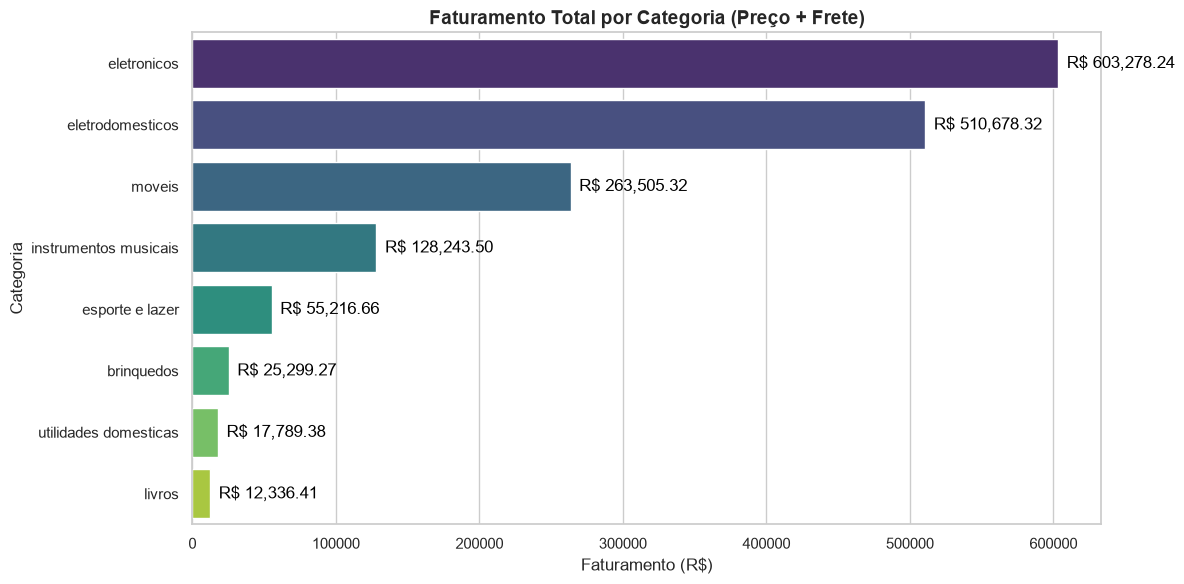

In [4]:
# Agrupando o faturamento usando o Valor Total (Preço + Frete)
fat_categoria = vendas_df.groupby('Categoria do Produto')['Valor Total'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=fat_categoria.values, y=fat_categoria.index, palette='viridis')

plt.title('Faturamento Total por Categoria (Preço + Frete)', fontweight='bold', fontsize=14)
plt.xlabel('Faturamento (R$)')
plt.ylabel('Categoria')

# Adicionando os valores diretamente nas barras do gráfico para facilitar a leitura
for i, v in enumerate(fat_categoria.values):
    ax.text(v + (max(fat_categoria.values)*0.01), i, f'R$ {v:,.2f}', color='black', va='center')

plt.tight_layout()
plt.show()

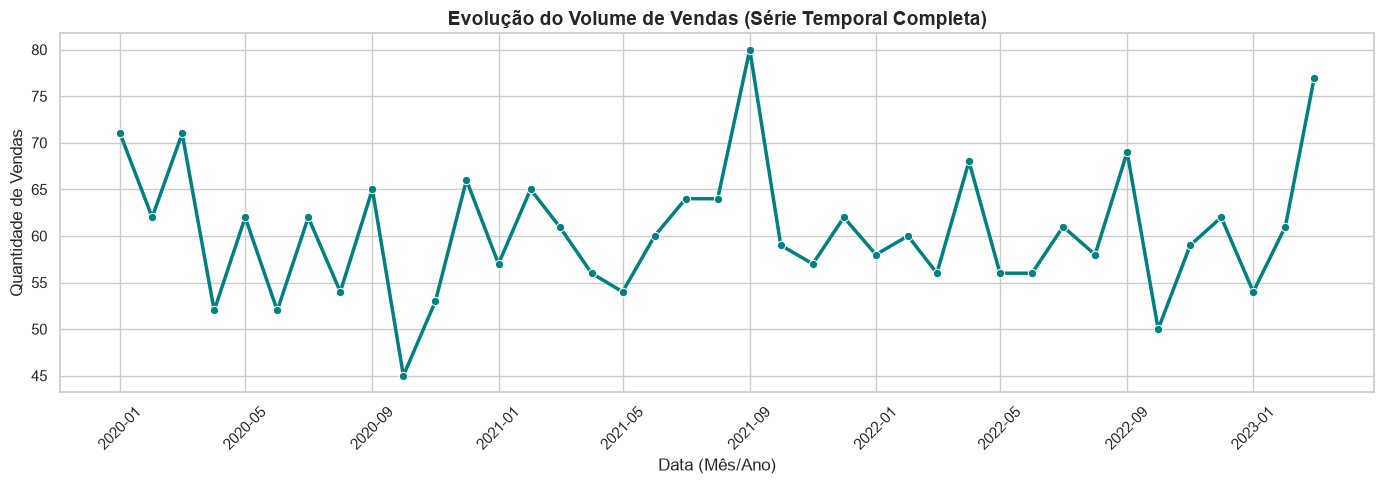

In [5]:
# Contando o volume de vendas por Ano e Mês (Série Histórica Contínua)
vendas_mes = vendas_df.groupby('Ano_Mes').size()

plt.figure(figsize=(14, 5))
# Convertendo o índice de volta para timestamp apenas para o plot funcionar perfeitamente
vendas_mes.index = vendas_mes.index.to_timestamp()

sns.lineplot(x=vendas_mes.index, y=vendas_mes.values, marker='o', color='teal', linewidth=2.5)

plt.title('Evolução do Volume de Vendas (Série Temporal Completa)', fontweight='bold', fontsize=14)
plt.xlabel('Data (Mês/Ano)')
plt.ylabel('Quantidade de Vendas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\crech\AppData\Local\Temp\ipykernel_24424\3362651446.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=vendas_df, x='Avaliação da compra', y='Frete', palette='coolwarm')


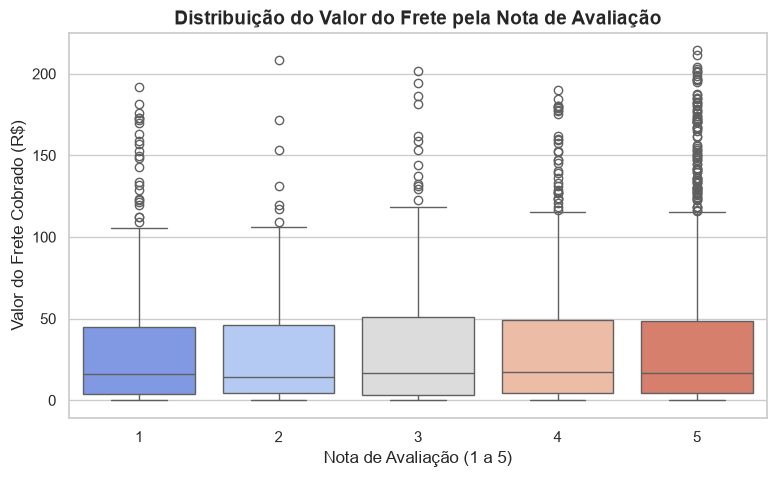

In [6]:
# Avaliando se notas mais baixas (1 e 2) estão ligadas a fretes mais caros
plt.figure(figsize=(9, 5))
sns.boxplot(data=vendas_df, x='Avaliação da compra', y='Frete', palette='coolwarm')

plt.title('Distribuição do Valor do Frete pela Nota de Avaliação', fontweight='bold', fontsize=14)
plt.xlabel('Nota de Avaliação (1 a 5)')
plt.ylabel('Valor do Frete Cobrado (R$)')
plt.show()

In [7]:
# Calculando KPIs dinamicamente para o relatório executivo
faturamento_total = vendas_df['Valor Total'].sum()
ticket_medio = vendas_df['Valor Total'].mean()
produto_mais_vendido = vendas_df['Produto'].value_counts().index[0]
qtde_mais_vendido = vendas_df['Produto'].value_counts().iloc[0]
categoria_top = fat_categoria.index[0]
nota_media = vendas_df['Avaliação da compra'].mean()

# Gerando o print formatado
print("="*60)
print(" 📊 RELATÓRIO EXECUTIVO DE VENDAS - RESULTADOS FINAIS")
print("="*60)
print(f"📌 FATURAMENTO E TICKET:")
print(f" - Faturamento Total Gerado: R$ {faturamento_total:,.2f}")
print(f" - Ticket Médio por Compra: R$ {ticket_medio:,.2f}")
print("\n📌 DESTAQUES DE PRODUTOS:")
print(f" - Categoria mais rentável: {categoria_top}")
print(f" - Produto mais vendido: {produto_mais_vendido} ({qtde_mais_vendido} unidades vendidas)")
print("\n📌 SATISFAÇÃO DO CLIENTE:")
print(f" - Nota Média de Avaliação: {nota_media:.2f} / 5.00")
print("="*60)

 📊 RELATÓRIO EXECUTIVO DE VENDAS - RESULTADOS FINAIS
📌 FATURAMENTO E TICKET:
 - Faturamento Total Gerado: R$ 1,616,347.09
 - Ticket Médio por Compra: R$ 685.18

📌 DESTAQUES DE PRODUTOS:
 - Categoria mais rentável: eletronicos
 - Produto mais vendido: Micro-ondas (60 unidades vendidas)

📌 SATISFAÇÃO DO CLIENTE:
 - Nota Média de Avaliação: 3.98 / 5.00


KeyError: 'Estado'

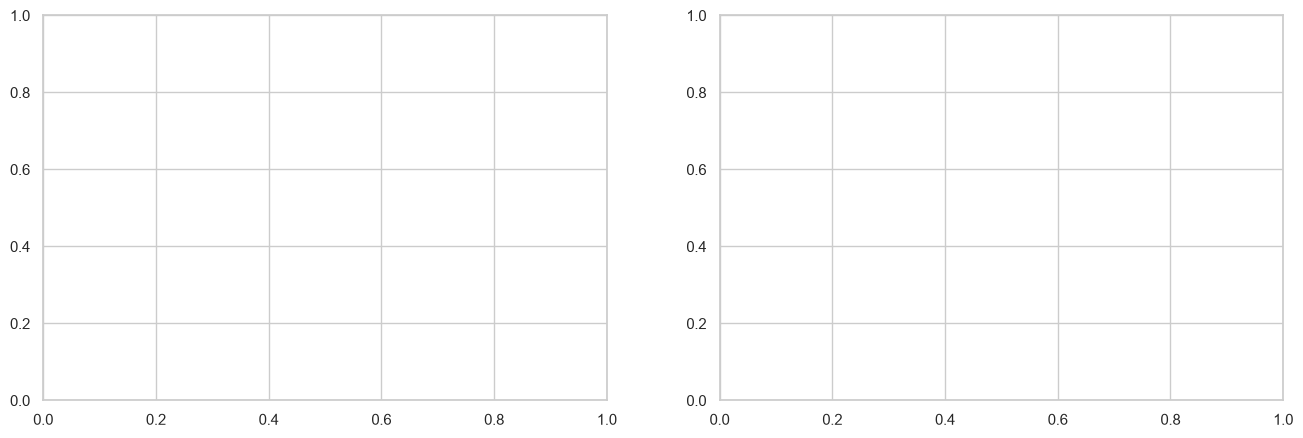

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico: Vendas por Estado
vendas_estado = vendas_df['Local da compra'].value_counts().head(10) # Pegando os 10 maiores para não poluir
sns.barplot(x=vendas_estado.values, y=vendas_estado.index, palette='Blues_r', ax=ax[0])
ax[0].set_title('Top 10 Estados com Maior Quantidade de Vendas', fontweight='bold')
ax[0].set_xlabel('Quantidade de Vendas')
ax[0].set_ylabel('Estado')

# 2. Gráfico: Formas de Pagamento
pagamento = vendas_df['Tipo de pagamento'].value_counts()
sns.barplot(x=pagamento.values, y=pagamento.index, palette='magma', ax=ax[1])
ax[1].set_title('Formas de Pagamento Mais Utilizadas', fontweight='bold')
ax[1].set_xlabel('Quantidade de Utilizações')
ax[1].set_ylabel('Método de Pagamento')

plt.tight_layout()
plt.show()